Potrebno je:  
1. Prikupiti i pripremiti skup CT slika s prisutnim i bez prisutnog krvarenja.
2. Provesti predobradu slika (filtriranje šuma, normalizacija, poboljšanje kontrasta).
3. Razviti metode za izdvajanje značajki i implementirati algoritam za klasifikaciju slika.
4. Vizualizirati i evaluirati rezultate (npr. točnost, preciznost, matrica zabune).
---

# Detekcija intracerebralnog krvarenja na CT slikama mozga

Sudionici projekta:

1. Nela Štubelj
2. Anja Obuljen
3. Karla Budimir
4. Marko Sršić

In [ ]:
import os
import cv2
import pandas as pd
from sklearn.manifold import TSNE
from skimage.feature import local_binary_pattern, graycomatrix, graycoprops, hog
from scipy.fft import fft2
from skimage.measure import regionprops, label
from skimage.morphology import convex_hull_image
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.decomposition import PCA
from lightgbm import LGBMClassifier
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
import numpy as np
import shap
import seaborn as sns

# 1. Učitavanje skupa podataka ✅

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
# import os
# print(os.listdir("/content/drive/MyDrive"))

In [ ]:
BASE_DIR = "/content/drive/MyDrive/Asub projekt/dataset"

LABELS_CSV = os.path.join(BASE_DIR, "labels.csv")
IMGS_DIR   = os.path.join(BASE_DIR, "head_ct", "head_ct")
print(os.path.isfile(LABELS_CSV))
print(os.path.isdir(IMGS_DIR))

True
True


In [ ]:
import glob
import re

labels = pd.read_csv(LABELS_CSV, skipinitialspace=True)
labels.columns = labels.columns.str.strip()
labels["id"] = labels["id"].astype(int)

all_imgs = sorted(glob.glob(os.path.join(IMGS_DIR, "*.png")))
def extract_id(path):
    m = re.findall(r"(\d+)", os.path.basename(path))
    return int(m[-1]) if m else None

idx = pd.DataFrame({"path": all_imgs})
idx["id"] = idx["path"].map(extract_id).astype(int)

df = labels.merge(idx, on="id", how="inner")

print("Distribucija labela:")
print(df["hemorrhage"].value_counts().rename({0:"bez krvarenja",1:"krvarenje"}))
print("Ukupno:", len(df))
df.head()

Distribucija labela:
hemorrhage
krvarenje        100
bez krvarenja    100
Name: count, dtype: int64
Ukupno: 200


,id,hemorrhage,path
0,0,1,/content/drive/MyDrive/Asub projekt/dataset/he...
1,1,1,/content/drive/MyDrive/Asub projekt/dataset/he...
2,2,1,/content/drive/MyDrive/Asub projekt/dataset/he...
3,3,1,/content/drive/MyDrive/Asub projekt/dataset/he...
4,4,1,/content/drive/MyDrive/Asub projekt/dataset/he...


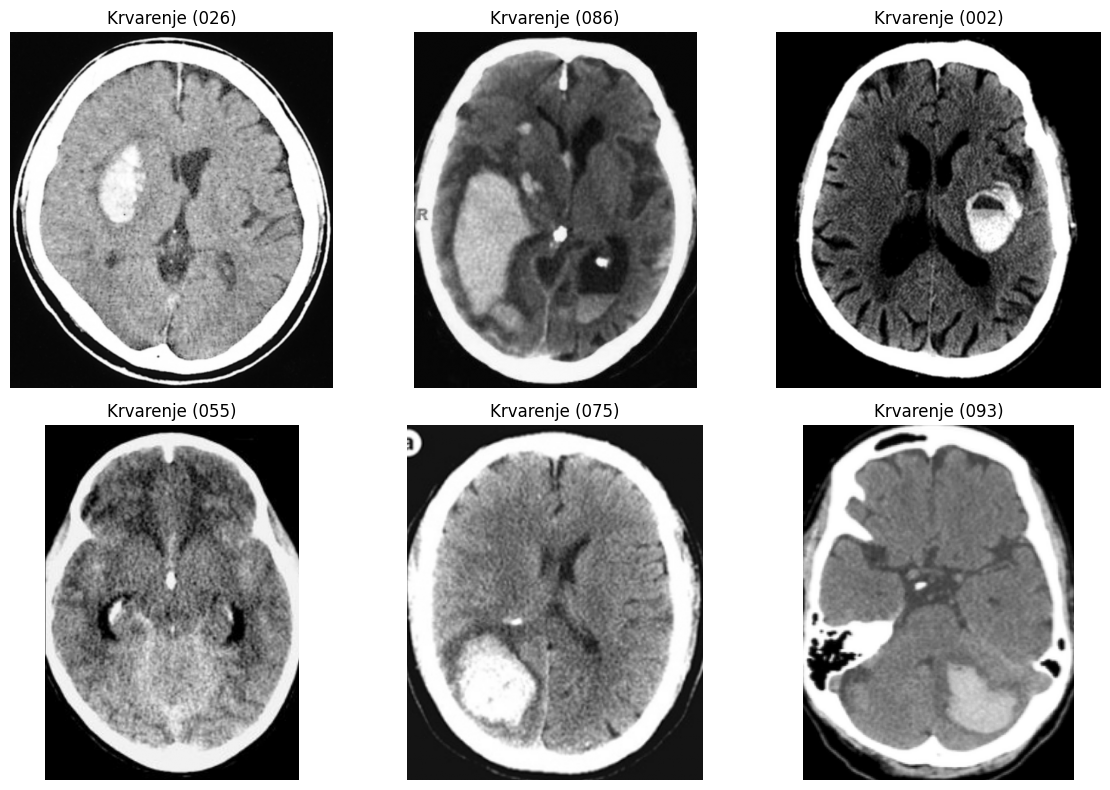

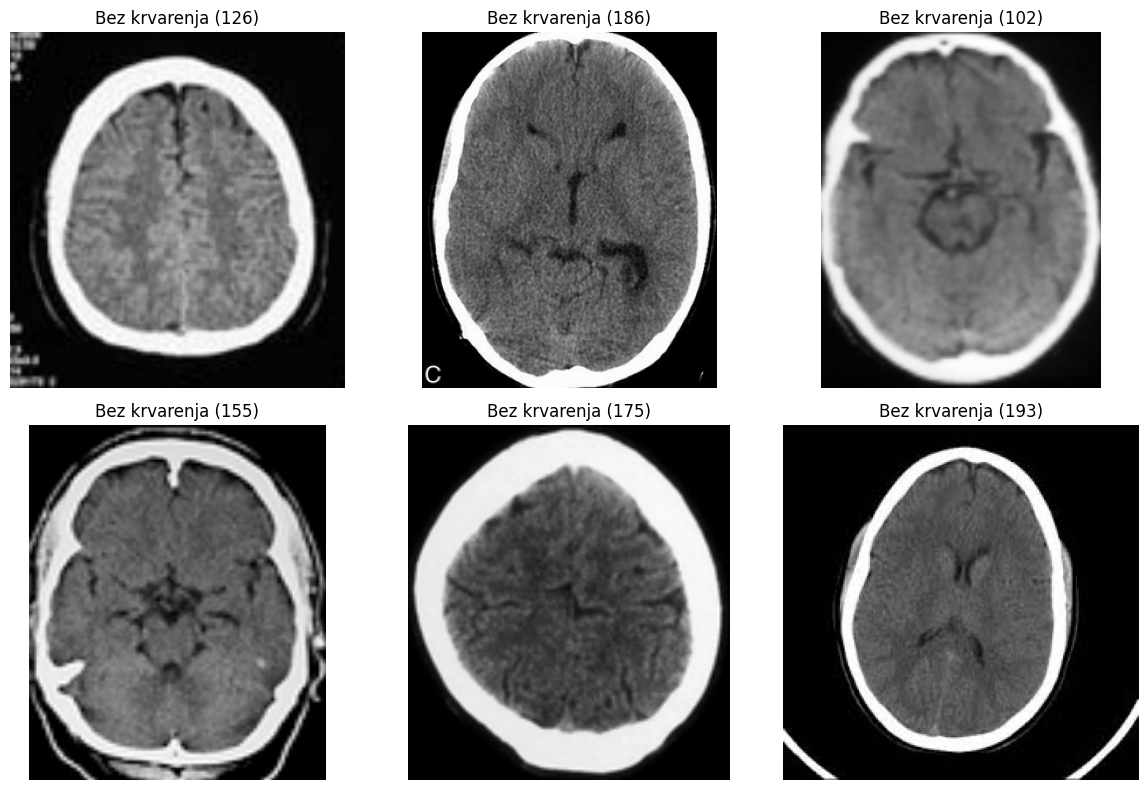

In [ ]:
def show_samples(label, n=6, title=""):
    sub = df[df["hemorrhage"] == label].sample(n=min(n, (df["hemorrhage"]==label).sum()), random_state=0)
    cols = 3
    rows = (len(sub) + cols - 1) // cols
    plt.figure(figsize=(4*cols, 4*rows))
    for i, r in enumerate(sub.itertuples()):
        img = cv2.imread(r.path, cv2.IMREAD_GRAYSCALE)
        plt.subplot(rows, cols, i+1)
        plt.imshow(img, cmap="gray")
        plt.axis("off")
        plt.title(f"{title} ({r.id:03d})")
    plt.tight_layout()
    plt.show()

show_samples(1, title="Krvarenje")
show_samples(0, title="Bez krvarenja")

Komentar : Krvarenja se najčešće manifestiraju kao svijetla, kompaktna područja nepravilnog oblika, dok okolno moždano tkivo ima niže intenzitete sivih tonova.

# 2. Predobrada slika ✅



## 2.1 Normalizacija veličine i poboljšanje kvalitete slike

U ovom koraku provedena je predobrada CT slika s ciljem standardizacije ulaznih podataka i poboljšanja vidljivosti relevantnih struktura mozga, posebice područja intracerebralnog krvarenja.

Svaka slika najprije je skalirana na standardnu veličinu (224 × 224 piksela) kako bi se osigurala konzistentnost ulaza za daljnju analizu i primjenu algoritama strojnog učenja. Time se smanjuje varijabilnost uzrokovana različitim rezolucijama izvornog skupa podataka.

## 2.2 Uklanjanje šuma (Gaussian filtriranje)

Nakon promjene veličine, na sliku je primijenjen Gaussov filtar s ciljem smanjenja šuma i sitnih artefakata prisutnih u CT slikama.
Gaussian filtriranje zaglađuje sliku ublažavanjem lokalnih varijacija intenziteta, pri čemu se zadržava globalna struktura slike i anatomski oblici.

Ovaj korak je posebno važan jer šum može negativno utjecati na izdvajanje teksturalnih značajki i rubova u kasnijim fazama obrade.

Napomena: u kontekstu CT slika intracerebralnog krvarenja postoji opasnost da malo krvarenje izgleda kao "šum". Iz tog razloga koristi se blagi Gaussian filter kako se ne bi obrisali znakovi bolesti uslijed prevelikog zaglađivanja slike.

## 2.3 Poboljšanje kontrasta (CLAHE)

Kako bi se dodatno naglasile razlike u intenzitetu između zdravog moždanog tkiva i područja krvarenja, primijenjena je metoda CLAHE (Contrast Limited Adaptive Histogram Equalization).

Za razliku od klasične histogram ekvalizacije, CLAHE lokalno prilagođava kontrast slike unutar manjih regija, čime se izbjegava prenaglašavanje šuma i omogućuje bolja vidljivost struktura u područjima s niskim kontrastom.


In [ ]:
def preprocess_image(gray, size=224):
    if gray is None:
        return None
    # resize
    img_resized = cv2.resize(gray, (size, size), interpolation=cv2.INTER_AREA)

    # uklanjanje šuma Gaussian filterom
    img_denoised = cv2.GaussianBlur(img_resized, (3,3), 0)

    # poboljšanje kontrasta
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    img_contrast = clahe.apply(img_denoised)

    # normalnizacija 0-1
    img_final = img_contrast / 255.0

    return img_final, img_contrast

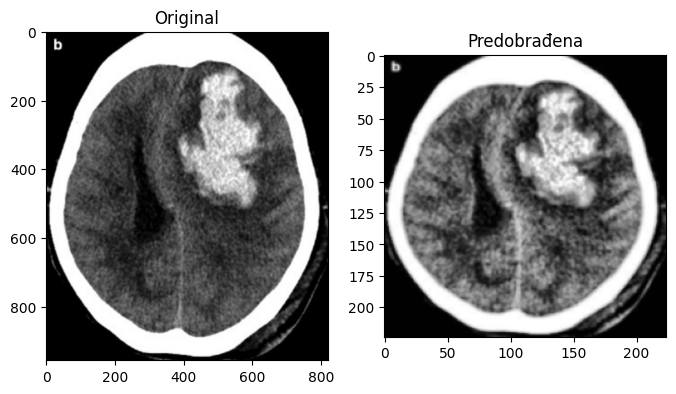

In [ ]:
img = cv2.imread(df.iloc[0].path, cv2.IMREAD_GRAYSCALE)
img_norm, img_contrast = preprocess_image(img)

plt.figure(figsize=(8,5))

plt.subplot(121); plt.imshow(img, cmap="gray");  plt.title("Original")
plt.subplot(122); plt.imshow(img_contrast, cmap="gray"); plt.title("Predobrađena")
# plt.subplot(133); plt.imshow(img_norm, cmap="gray"); plt.title("Predobrađena (NORM)")

plt.show()

Na slici je prikazana usporedba originalne CT slike i predobrađene slike nakon primjene svih opisanih koraka.

Uočava se da:  
- predobrađena slika ima izraženiji kontrast između krvarenja i okolnog tkiva,
- rubovi i strukture mozga su jasnije definirani,
- područje krvarenja postaje vizualno uočljivije zbog veće razlike u intenzitetu sivih tonova,
- smanjen je utjecaj šuma, što olakšava daljnju segmentaciju i klasifikaciju.

Ovakva predobrada stvara kvalitetniji ulaz za izdvajanje značajki i treniranje klasifikacijskog modela.

# 3. Segmentacija regije interesa (ROI) - izdvajanje mozga ✅

U ovom koraku provodimo segmentaciju regije interesa (ROI) s ciljem izdvajanja područja mozga i uklanjanja pozadine (crna pozadina, rubovi, oznake, okviri) koje ne nose korisnu informaciju za detekciju krvarenja.
Time se smanjuje utjecaj irelevantnih piksela na kasnije korake (izdvajanje značajki i klasifikaciju), a model se usmjerava na anatomsku regiju gdje se krvarenje stvarno pojavljuje.

ROI se dobiva jednostavnom i interpretabilnom procedurom:

1. Thresholding (Otsu) kako bismo odvojili glavu/mozak od pozadine,

2. Morfološke operacije (closing + opening) za popunjavanje rupa i uklanjanje šuma,

3. Zadržavanje najveće povezane komponente (LCC - Largest Connected Component) kako bismo zadržali samo glavnu regiju glave/mozga (a uklonili artefakte u kutovima),

4. Primjena maske na predobrađenu sliku (dobivamo “masked ROI”).

Uočavamo da nakon ROI segmentacije nestaje većina pozadine i rubnih artefakata, dok mozak ostaje u fokusu. To je korisno jer kasnije značajke (npr. tekstura, rubovi, udio svijetlih piksela) postaju stabilnije i manje ovise o pozadini.

In [ ]:
def apply_mask(img, mask):
    return cv2.bitwise_and(img, img, mask=mask)

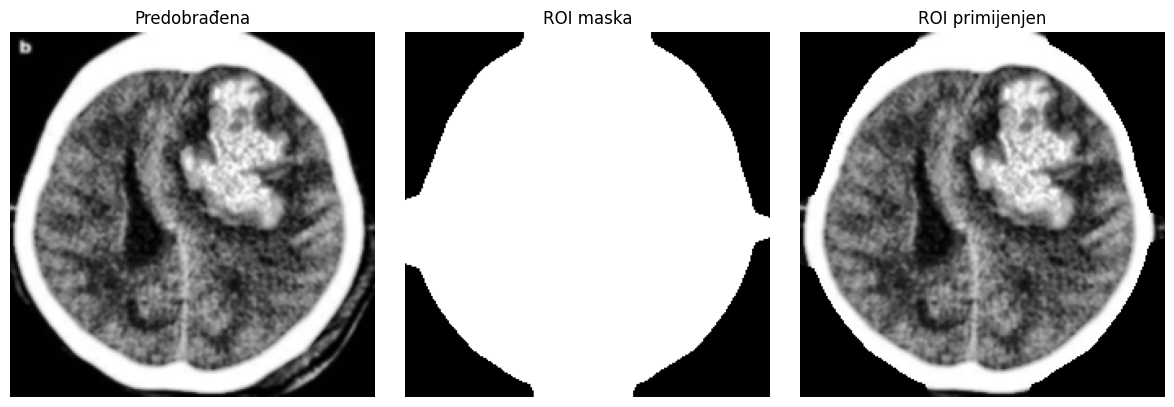

In [ ]:
import cv2
import numpy as np
from scipy.ndimage import binary_fill_holes

def brain_roi_mask(gray_224):
    """
    Ulaz:
        gray_224 - grayscale CT slice (0–255), resizean i predobrađen
    Izlaz:
        binarna maska (0/255) koja pokriva CIJELU unutrašnjost lubanje
    """

    # prag za kost (svijetle vrijednosti)
    bone_thresh = cv2.threshold(
        gray_224, 200, 255, cv2.THRESH_BINARY
    )[1]

    # morfološko zatvaranje
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))
    bone_thresh = cv2.morphologyEx(
        bone_thresh, cv2.MORPH_CLOSE, kernel, iterations=2
    )

    # najveća povezana komponenta
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
        bone_thresh, connectivity=8
    )

    if num_labels < 2:
        return np.zeros_like(gray_224)

    largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    skull = np.zeros_like(bone_thresh)
    skull[labels == largest] = 255

    # popunjavanje unutrašnjosti lubanje
    skull_filled = binary_fill_holes(skull > 0)


    skull_filled = skull_filled.astype(np.uint8) * 255
    skull_filled = cv2.erode(
        skull_filled,
        cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)),
        iterations=1
    )

    return skull_filled

img = cv2.imread(df.iloc[0].path, cv2.IMREAD_GRAYSCALE)
_, proc = preprocess_image(img, size=224)
mask = brain_roi_mask(proc)
roi  = apply_mask(proc, mask)

plt.figure(figsize=(12,4))
plt.subplot(1,3,1); plt.imshow(proc, cmap="gray"); plt.title("Predobrađena"); plt.axis("off")
plt.subplot(1,3,2); plt.imshow(mask, cmap="gray"); plt.title("ROI maska"); plt.axis("off")
plt.subplot(1,3,3); plt.imshow(roi,  cmap="gray"); plt.title("ROI primijenjen"); plt.axis("off")
plt.tight_layout()
plt.show()

ROI prije/poslije na više slika i obje klase

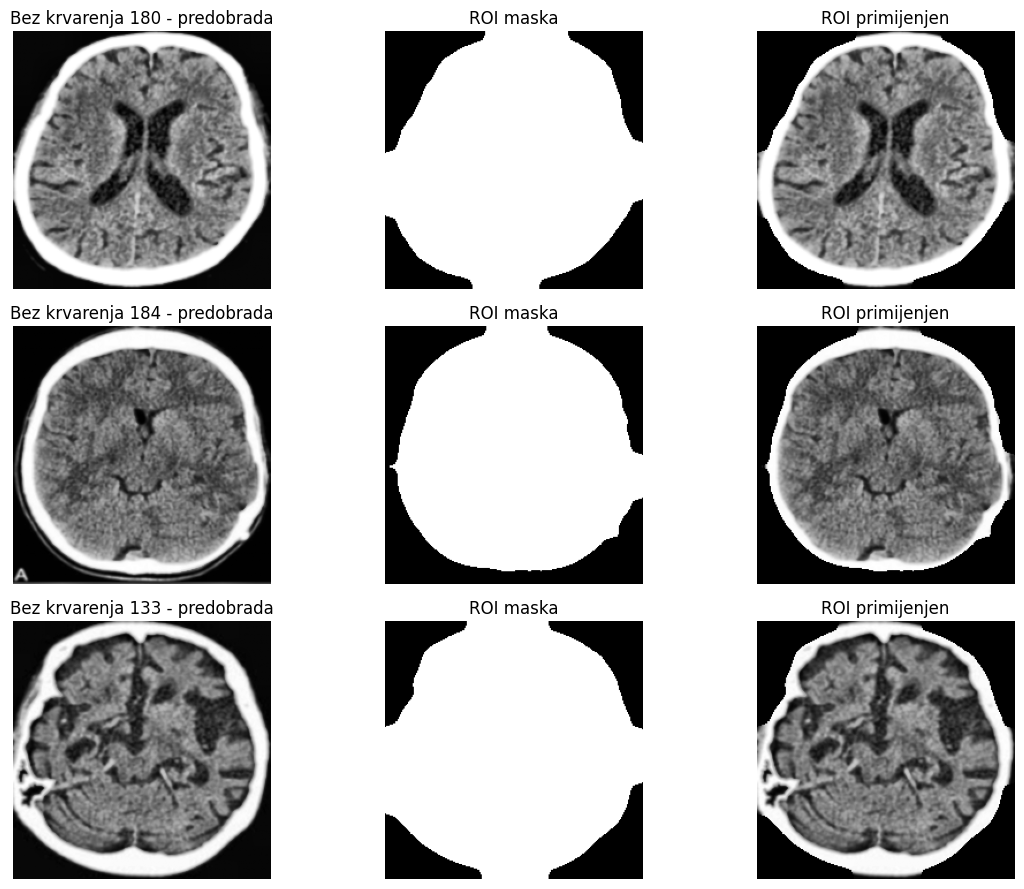

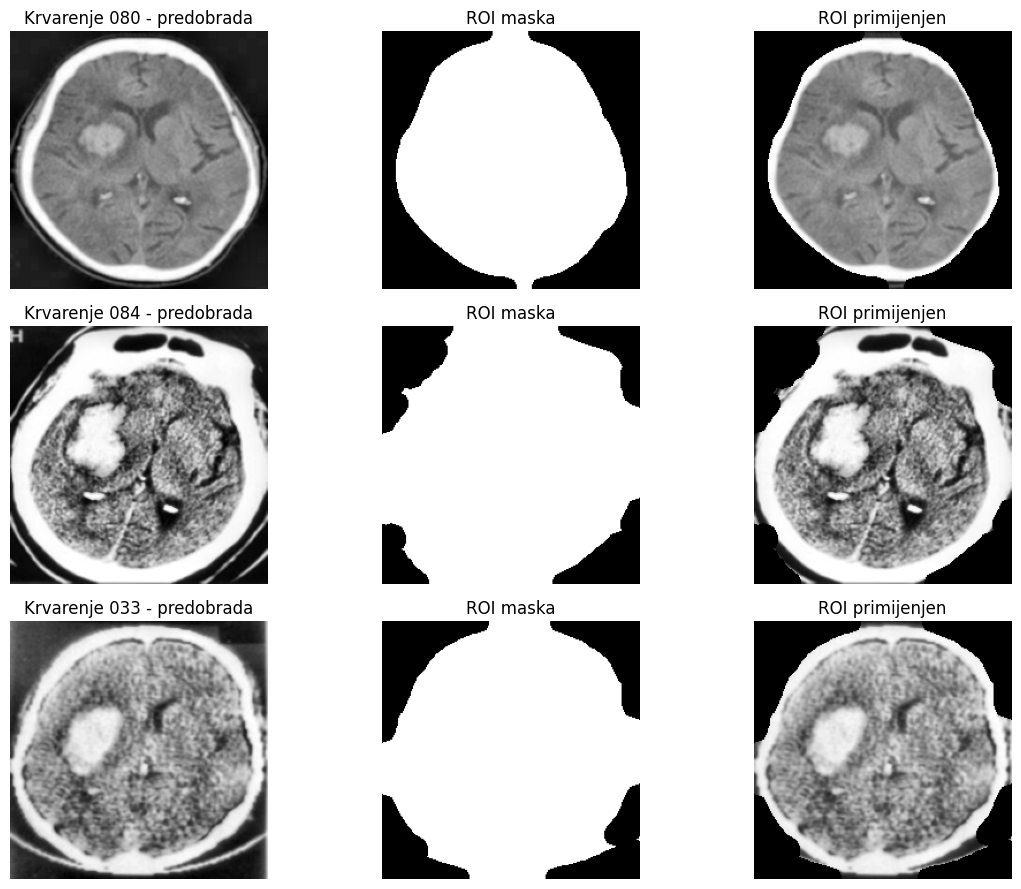

In [ ]:
def show_roi_examples(label_value, n=1, title=""):
    sub = df[df["hemorrhage"] == label_value].sample(n, random_state=1)

    plt.figure(figsize=(12, 3*n))
    for i, r in enumerate(sub.itertuples(), start=1):
        img = cv2.imread(r.path, cv2.IMREAD_GRAYSCALE)
        _, proc = preprocess_image(img, size=224)
        mask = brain_roi_mask(proc)
        roi  = apply_mask(proc, mask)

        plt.subplot(n, 3, (i-1)*3 + 1)
        plt.imshow(proc, cmap="gray"); plt.axis("off")
        plt.title(f"{title} {int(r.id):03d} - predobrada")

        plt.subplot(n, 3, (i-1)*3 + 2)
        plt.imshow(mask, cmap="gray"); plt.axis("off")
        plt.title("ROI maska")

        plt.subplot(n, 3, (i-1)*3 + 3)
        plt.imshow(roi, cmap="gray"); plt.axis("off")
        plt.title("ROI primijenjen")

    plt.tight_layout()
    plt.show()

show_roi_examples(0, n=3, title="Bez krvarenja")
show_roi_examples(1, n=3, title="Krvarenje")

# 4. Izdvajanje značajki (*Feature extraction*)

Nakon provedene predobrade i segmentacije regije interesa (ROI), sljedeći korak je izdvajanje značajki koje kvantitativno opisuju sadržaj CT slike. Cilj ovog koraka je pretvoriti vizualne informacije iz slike u numeričke deskriptore koji omogućuju razlikovanje slika s intracerebralnim krvarenjem od onih bez krvarenja.

S obzirom na prirodu CT slika mozga i karakteristike intracerebralnog krvarenja, u ovom projektu koriste se tri komplementarne skupine značajki: intenzitetske, rubne i teksturalne značajke.

## 4.1  Intenzitetske značajke

Intracerebralno krvarenje na CT slikama tipično se očituje kao hiperdenzna (svjetlija) regija u odnosu na okolno moždano tkivo. Zbog toga su značajke temeljene na intenzitetu piksela vrlo informativne.

*Kada kažemo da je krvarenje "hiperdenzno", to znači da je krv gušća od okolnog mozga i zato "svijetli" na slici.*

U ovom koraku iz ROI-a se izdvajaju:

1. Srednja vrijednost intenziteta (mean) – daje uvid u ukupnu svjetlinu regije.

2. Standardna devijacija intenziteta (std) – mjeri varijabilnost sivih tonova unutar ROI-a.

3. Histogram sivih tonova – opisuje raspodjelu intenziteta piksela i omogućuje uočavanje većeg udjela svijetlih vrijednosti kod slika s krvarenjem.

4. Postotak svijetlih piksela – definiran kao udio piksela iznad određenog praga, što direktno modelira prisutnost hiperdenznih područja karakterističnih za krvarenje.



Features for Hemorrhage Image
Mean: 140.71
Std:  63.23
Skew: 0.15
Kurt: -1.14
Bright %: 0.3711

 Features for No Hemorrhage Image
Mean: 112.41
Std:  70.80
Skew: 0.88
Kurt: -0.70
Bright %: 0.2385


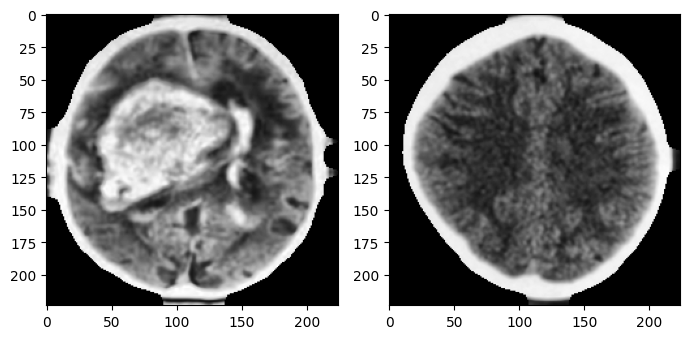

In [ ]:
import numpy as np
import scipy.stats

def get_intensity_features(img, mask):
    brain_pixels = img[mask > 0].ravel()
    if len(brain_pixels) == 0:
        return 0, 0, 0, 0, 0
    mean_intensity = np.mean(brain_pixels)
    std_intensity = np.std(brain_pixels)
    skewness = scipy.stats.skew(brain_pixels)
    kurtosis = scipy.stats.kurtosis(brain_pixels)

    bright_threshold = 160
    bright_pixels_count = np.sum(brain_pixels > bright_threshold)
    bright_pixel_ratio = bright_pixels_count / len(brain_pixels)

    return mean_intensity, std_intensity, skewness, kurtosis, bright_pixel_ratio


hem_path = df[df["hemorrhage"] == 1].iloc[10].path
no_hem_path = df[df["hemorrhage"] == 0].iloc[71].path


img_hem = cv2.imread(hem_path, cv2.IMREAD_GRAYSCALE)
_, proc_hem = preprocess_image(img_hem)
mask_hem = brain_roi_mask(proc_hem)
roi_hem = apply_mask(proc_hem, mask_hem)
feats_int_hem = get_intensity_features(roi_hem, mask_hem)

print("Features for Hemorrhage Image")
print(f"Mean: {feats_int_hem[0]:.2f}")
print(f"Std:  {feats_int_hem[1]:.2f}")
print(f"Skew: {feats_int_hem[2]:.2f}")
print(f"Kurt: {feats_int_hem[3]:.2f}")
print(f"Bright %: {feats_int_hem[4]:.4f}")


img_no_hem = cv2.imread(no_hem_path, cv2.IMREAD_GRAYSCALE)
_, proc_no_hem = preprocess_image(img_no_hem)
mask_no_hem = brain_roi_mask(proc_no_hem)
roi_no_hem = apply_mask(proc_no_hem, mask_no_hem)
feats_int_no_hem = get_intensity_features(roi_no_hem, mask_no_hem)

print("\n Features for No Hemorrhage Image")
print(f"Mean: {feats_int_no_hem[0]:.2f}")
print(f"Std:  {feats_int_no_hem[1]:.2f}")
print(f"Skew: {feats_int_no_hem[2]:.2f}")
print(f"Kurt: {feats_int_no_hem[3]:.2f}")
print(f"Bright %: {feats_int_no_hem[4]:.4f}")

plt.figure(figsize=(7, 5))
plt.subplot(121); plt.imshow(roi_hem, cmap="gray")
plt.subplot(122); plt.imshow(roi_no_hem, cmap="gray")
plt.tight_layout()
plt.show()

## 4.2 Značajke temeljene na rubovima

Krvarenja često stvaraju izražene granice između zahvaćenog područja i okolnog tkiva. Zbog toga se analiziraju rubne karakteristike slike unutar ROI-a.

Izvlače se sljedeće informacije:

1. Detekcija rubova (npr. Canny ili Sobel) kako bi se istaknule nagle promjene intenziteta.

2. Gustoća rubova (edge density) – omjer broja rubnih piksela i ukupnog broja piksela u ROI-u.

3. Prosječna jačina gradijenta – mjeri koliko su prijelazi intenziteta izraženi.

Slike s krvarenjem često pokazuju veću gustoću i jačinu rubova zbog nepravilnog oblika i oštrih prijelaza između krvarenja i normalnog moždanog tkiva.

Features for Hemorrhage Image
Avg Gradient: 117.89
Edge Density: 0.2173

 Features for No Hemorrhage Image
Avg Gradient: 101.63
Edge Density: 0.1063


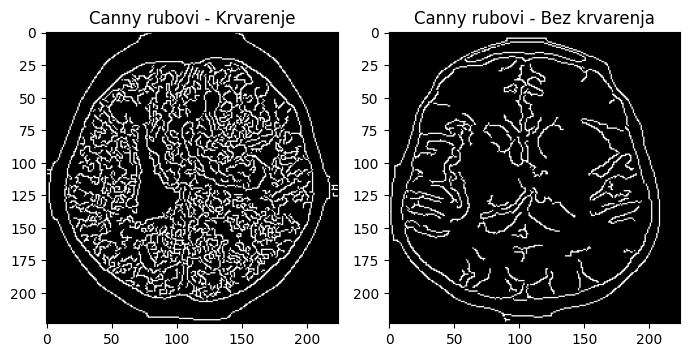

In [ ]:
def get_edge_features(img, mask):
    # prosječna jačina gradijenta (Sobel)
    sobelx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
    sobely = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
    # magnituda gradijenta: G = sqrt(Gx^2 + Gy^2)
    gradient_magnitude = np.sqrt(sobelx**2 + sobely**2)
    mean_gradient = np.mean(gradient_magnitude[mask > 0])

    # gustoća rubova
    edges = cv2.Canny(img, 100, 200)
    edges_masked = apply_mask(edges, mask)

    # gustoća = broj piksela ruba / ukupan broj piksela mozga
    brain_area = np.count_nonzero(mask)
    if brain_area == 0: return 0, 0

    edge_density = np.count_nonzero(edges_masked) / brain_area

    return mean_gradient, edge_density


hem_path = df[df["hemorrhage"] == 1].iloc[0].path
no_hem_path = df[df["hemorrhage"] == 0].iloc[0].path

img_hem = cv2.imread(hem_path, cv2.IMREAD_GRAYSCALE)
_, proc_hem = preprocess_image(img_hem)
mask_hem = brain_roi_mask(proc_hem)
roi_hem = apply_mask(proc_hem, mask_hem)
feats_edge_hem = get_edge_features(roi_hem, mask_hem)

print("Features for Hemorrhage Image")
print(f"Avg Gradient: {feats_edge_hem[0]:.2f}")
print(f"Edge Density: {feats_edge_hem[1]:.4f}")


img_no_hem = cv2.imread(no_hem_path, cv2.IMREAD_GRAYSCALE)
_, proc_no_hem = preprocess_image(img_no_hem)
mask_no_hem = brain_roi_mask(proc_no_hem)
roi_no_hem = apply_mask(proc_no_hem, mask_no_hem)
feats_edge_no_hem = get_edge_features(roi_no_hem, mask_no_hem)

print("\n Features for No Hemorrhage Image")
print(f"Avg Gradient: {feats_edge_no_hem[0]:.2f}")
print(f"Edge Density: {feats_edge_no_hem[1]:.4f}")


plt.figure(figsize=(7, 5))
edges_viz_hem = cv2.Canny(roi_hem, 100, 200)
plt.subplot(121); plt.imshow(edges_viz_hem, cmap='gray'); plt.title("Canny rubovi - Krvarenje")
edges_viz_no_hem = cv2.Canny(roi_no_hem, 100, 200)
plt.subplot(122); plt.imshow(edges_viz_no_hem, cmap='gray'); plt.title("Canny rubovi - Bez krvarenja")
plt.tight_layout()
plt.show()

## 4.3 Teksturalne značajke

Osim razlika u intenzitetu, tkivo zahvaćeno krvarenjem pokazuje i drukčiju teksturalnu strukturu u usporedbi sa zdravim moždanim tkivom. Kako bi se ta razlika kvantificirala, koriste se teksturalne značajke.

U projektu se razmatraju:

1. LBP (Local Binary Patterns) - lokalni deskriptori koji opisuju mikrostrukturu slike i osjetljivi su na nepravilnosti i granularnost teksture.

2. GLCM (Gray Level Co-occurrence Matrix) - statistički pristup koji opisuje prostorne odnose sivih tonova u slici.
Iz GLCM matrice moguće je izdvojiti značajke poput: kontrasta,homogenosti,energije,korelacije.



Features for Hemorrhage Image
Contrast:    623.27
Homogeneity: 0.43
Energy:      0.28
Correlation: 0.96
LBP Mean:    4.76
LBP Std:     2.10

Features for No Hemorrhage Image
Contrast:    508.39
Homogeneity: 0.44
Energy:      0.31
Correlation: 0.95
LBP Mean:    4.44
LBP Std:     1.77


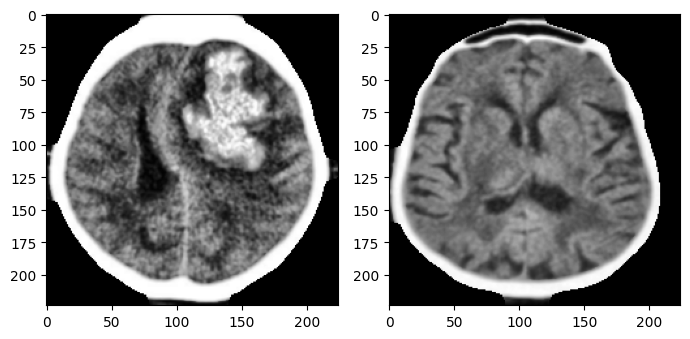

In [ ]:
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern

def get_texture_features(img, mask):

    glcm = graycomatrix(img, distances=[1], angles=[0], levels=256, symmetric=True, normed=True)

    # izdvajanje svojstava iz matrice
    contrast = graycoprops(glcm, 'contrast')[0, 0]
    homogeneity = graycoprops(glcm, 'homogeneity')[0, 0]
    energy = graycoprops(glcm, 'energy')[0, 0]
    correlation = graycoprops(glcm, 'correlation')[0, 0]

    lbp = local_binary_pattern(img, P=8, R=1, method='uniform')
    lbp_valid = lbp[mask > 0]
    if len(lbp_valid) == 0: return 0, 0, 0, 0, 0, 0

    lbp_mean = np.mean(lbp_valid)
    lbp_std = np.std(lbp_valid)

    return contrast, homogeneity, energy, correlation, lbp_mean, lbp_std


hem_path = df[df["hemorrhage"] == 1].iloc[0].path
no_hem_path = df[df["hemorrhage"] == 0].iloc[0].path


img_hem = cv2.imread(hem_path, cv2.IMREAD_GRAYSCALE)
_, proc_hem = preprocess_image(img_hem)
mask_hem = brain_roi_mask(proc_hem)
roi_hem = apply_mask(proc_hem, mask_hem)
feats_texture_hem = get_texture_features(roi_hem, mask_hem)

print("Features for Hemorrhage Image")
print(f"Contrast:    {feats_texture_hem[0]:.2f}")
print(f"Homogeneity: {feats_texture_hem[1]:.2f}")
print(f"Energy:      {feats_texture_hem[2]:.2f}")
print(f"Correlation: {feats_texture_hem[3]:.2f}")
print(f"LBP Mean:    {feats_texture_hem[4]:.2f}")
print(f"LBP Std:     {feats_texture_hem[5]:.2f}")


img_no_hem = cv2.imread(no_hem_path, cv2.IMREAD_GRAYSCALE)
_, proc_no_hem = preprocess_image(img_no_hem)
mask_no_hem = brain_roi_mask(proc_no_hem)
roi_no_hem = apply_mask(proc_no_hem, mask_no_hem)
feats_texture_no_hem = get_texture_features(roi_no_hem, mask_no_hem)

print("\nFeatures for No Hemorrhage Image")
print(f"Contrast:    {feats_texture_no_hem[0]:.2f}")
print(f"Homogeneity: {feats_texture_no_hem[1]:.2f}")
print(f"Energy:      {feats_texture_no_hem[2]:.2f}")
print(f"Correlation: {feats_texture_no_hem[3]:.2f}")
print(f"LBP Mean:    {feats_texture_no_hem[4]:.2f}")
print(f"LBP Std:     {feats_texture_no_hem[5]:.2f}")

plt.figure(figsize=(7, 5))
plt.subplot(121); plt.imshow(roi_hem, cmap="gray")
plt.subplot(122); plt.imshow(roi_no_hem, cmap="gray")
plt.tight_layout()
plt.show()

## 4.4 Formiranje vektora značajki

Sve izdvojene značajke (intenzitetske, rubne i teksturalne) kombiniraju se u jedinstveni vektor značajki za svaku sliku. Prije korištenja u modelima strojnog učenja, značajke se standardiziraju kako bi se osigurala usporedivost i stabilno učenje.

Ovako dobiveni vektori služe kao ulaz u modele klasifikacije u sljedećem koraku projekta.

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from tqdm import tqdm

feature_list = []

for index, row in tqdm(df.iterrows(), total=df.shape[0]):
    img_raw = cv2.imread(row.path, cv2.IMREAD_GRAYSCALE)
    _, img_proc = preprocess_image(img_raw)

    mask = brain_roi_mask(img_proc)
    roi_img = apply_mask(img_proc, mask)

    mean_val, std_val, skew, kurt, bright_ratio = get_intensity_features(roi_img, mask)                         # intenzitet
    grad_mean, edge_dens = get_edge_features(roi_img, mask)                                                     # rubovi
    contrast, homogeneity, energy, correlation, lbp_mean, lbp_std = get_texture_features(roi_img, mask)         #tekstura

    features = {
        'id': row.id,
        'label': row.hemorrhage,
        # Intenzitet
        'intensity_mean': mean_val,
        'intensity_std': std_val,
        'skewness': skew,
        'kurtosis': kurt,
        'bright_pixel_ratio': bright_ratio,
        # Rubovi
        'gradient_mean': grad_mean,
        'edge_density': edge_dens,
        # Tekstura
        'glcm_contrast': contrast,
        'glcm_homogeneity': homogeneity,
        'glcm_energy': energy,
        'glcm_correlation': correlation,
        'lbp_mean': lbp_mean,
        'lbp_std': lbp_std
    }
    feature_list.append(features)

df_features = pd.DataFrame(feature_list)
X = df_features.drop(['id', 'label'], axis=1)
y = df_features['label']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_final = pd.DataFrame(X_scaled, columns=X.columns)

print(f"Dimenzije vektora značajki: {X_final.shape}")
X_final.head()

100%|██████████| 200/200 [00:10<00:00, 19.64it/s]

Dimenzije vektora značajki: (200, 13)


,intensity_mean,intensity_std,skewness,kurtosis,bright_pixel_ratio,gradient_mean,edge_density,glcm_contrast,glcm_homogeneity,glcm_energy,glcm_correlation,lbp_mean,lbp_std
0,-0.442744,1.976557,0.041215,-0.548210,-0.058673,-0.000076,0.747954,0.750378,-0.078363,-0.309159,0.194090,1.274676,1.023854
1,0.273730,0.904099,-0.509768,-0.443590,0.616802,0.407776,1.217116,0.087424,-0.677499,-0.502061,0.433594,0.316741,1.324329
2,-1.088091,2.128865,-0.095013,-0.356162,-0.373835,1.093429,1.230993,2.093448,0.904331,0.766110,-0.769386,1.609433,1.371124
3,-0.711154,2.316118,-0.212767,-0.506230,-0.041360,0.887111,1.104717,2.022080,0.236618,0.098193,-0.399331,1.280987,1.003783
4,0.136169,-0.484345,0.124116,-0.139544,-0.010485,0.202340,0.421168,1.163953,-0.131252,0.071037,-0.538859,-0.442979,0.075263


# 5. Modeli strojnog učenja

Isprobali smo sljedeće modele:
- Logistička regresija
- SVM
- Random Forest
- XGBoost
- MLP - neuronska mreža

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, recall_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

X_train, X_test, y_train, y_test = train_test_split(X_final, y, test_size=0.20, random_state=42, stratify=y)

print(f"Trening set: {X_train.shape[0]} slika")
print(f"Test set:    {X_test.shape[0]} slika")

Trening set: 160 slika
Test set:    40 slika


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.neural_network import MLPClassifier

models = {
    "Logistička Regresija": LogisticRegression(random_state=42, max_iter=5000, C=1.0, solver="lbfgs"),
    "SVM (RBF Kernel)": SVC(random_state=42, kernel="rbf", C=10.0, gamma='scale', probability=True),
    "Random Forest": RandomForestClassifier(random_state=42, n_estimators=500, max_features="sqrt", min_samples_leaf=2),
    "XGBoost": XGBClassifier(random_state=42, n_estimators=500, max_depth=6, learning_rate=0.05, subsample=0.8, eval_metric="logloss"),
    "Neuronska mreža (MLP)": MLPClassifier(random_state=42, hidden_layer_sizes=(64, 32), max_iter=1000, solver='adam', activation='relu', alpha=0.0001)
}

# 6. Evaluacija i usporedba modela

NAJVAŽNIJA ZNAČAJKA: Recall - Odziv
- najvažniji broj u medicini: *od svih ljudi koji STVARNO imaju krvarenje, koliko ih je model prepoznao?*
- često ćemo radije prihvatiti malo manju ukupnu točnost, samo da Recall bude što bliže 1.00

In [ ]:
results = {}

print(f"{'Model':<25} | {'Accuracy [Test (Train)]':<28} | {'Recall [Test (Train)]':<28}")
print("-" * 85)

for name, model in models.items():
    print(f"\nTrain: {name}...")

    model.fit(X_train, y_train)
    y_test_pred = model.predict(X_test)
    y_train_pred = model.predict(X_train)

    acc_train, rec_train  = accuracy_score(y_train, y_train_pred), recall_score(y_train, y_train_pred, pos_label=1)
    acc_test, rec_test = accuracy_score(y_test, y_test_pred), recall_score(y_test, y_test_pred, pos_label=1)

    results[name] = {'Accuracy': acc_test, 'Recall': rec_test}


    acc_str = f"{acc_test:.4f} ({acc_train:.4f})"
    rec_str = f"{rec_test:.4f} ({rec_train:.4f})"
    print(f"\033[A{name:<25} | {acc_str:<28} | {rec_str:<28}")
    print("-" * 85)

best_acc_model = max(results, key=lambda x: results[x]['Accuracy'])
print(f"\n Najveća Točnost: {best_acc_model} -> {results[best_acc_model]['Accuracy']:.4f}")
best_recall_model = max(results, key=lambda x: results[x]['Recall'])
print(f" Najveći Odziv:   {best_recall_model} -> {results[best_recall_model]['Recall']:.4f}")

Model                     | Accuracy [Test (Train)]      | Recall [Test (Train)]       
-------------------------------------------------------------------------------------

Train: Logistička Regresija...
Logistička Regresija      | 0.7000 (0.7188)              | 0.6500 (0.7000)             
-------------------------------------------------------------------------------------

Train: SVM (RBF Kernel)...
SVM (RBF Kernel)          | 0.7250 (0.9062)              | 0.7000 (0.8250)             
-------------------------------------------------------------------------------------

Train: Random Forest...
Random Forest             | 0.6500 (0.9938)              | 0.5500 (1.0000)             
-------------------------------------------------------------------------------------

Train: XGBoost...
XGBoost                   | 0.6500 (1.0000)              | 0.6000 (1.0000)             
-------------------------------------------------------------------------------------

Train: Neuronska mreža (M

Čini se da najbolju točnost i odziv daje neuronska mreža.

<>:4: SyntaxWarning: invalid escape sequence '\T'
<>:4: SyntaxWarning: invalid escape sequence '\T'
/tmp/ipython-input-3554601809.py:4: SyntaxWarning: invalid escape sequence '\T'
  print("\Test Skup")


\Test Skup
                       Accuracy  Recall
Neuronska mreža (MLP)     0.800    0.85
SVM (RBF Kernel)          0.725    0.70
Logistička Regresija      0.700    0.65
Random Forest             0.650    0.55
XGBoost                   0.650    0.60


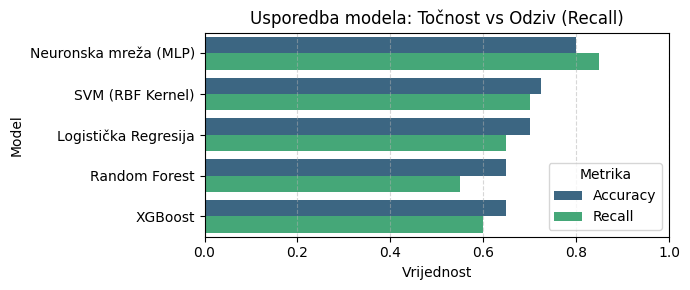

In [ ]:
df_results = pd.DataFrame(results).T
df_results = df_results.sort_values(by='Accuracy', ascending=False)

print("\Test Skup")
print(df_results)

df_melted = df_results.reset_index().melt(id_vars='index', var_name='Metrika', value_name='Vrijednost')
df_melted.rename(columns={'index': 'Model'}, inplace=True)

plt.figure(figsize=(7, 3))
sns.barplot(data=df_melted, x='Vrijednost', y='Model', hue='Metrika', palette="viridis")
plt.title("Usporedba modela: Točnost vs Odziv (Recall)")
plt.xlim(0, 1.0)
plt.legend(title="Metrika")
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Analizirajmo detaljnije najbolji model - neuronsku mrežu:

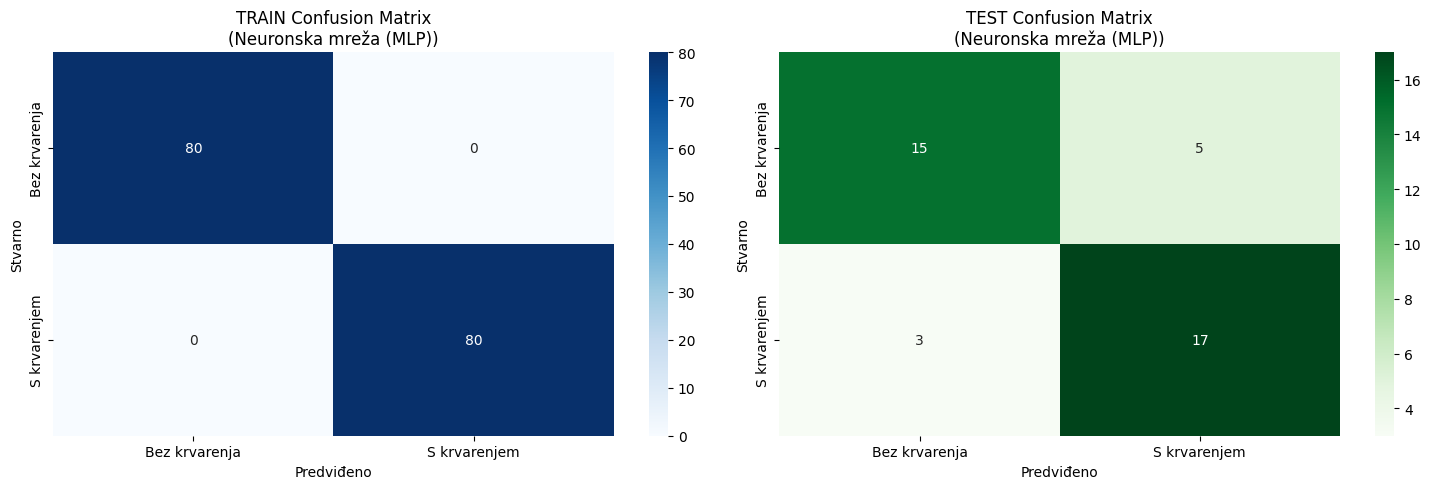

DETALJNA ANALIZA ZA POBJEDNIKA: Neuronska mreža (MLP)

CLASSIFICATION REPORT (TRAIN)
               precision    recall  f1-score   support

Bez krvarenja       1.00      1.00      1.00        80
 S krvarenjem       1.00      1.00      1.00        80

     accuracy                           1.00       160
    macro avg       1.00      1.00      1.00       160
 weighted avg       1.00      1.00      1.00       160


CLASSIFICATION REPORT (TEST)
               precision    recall  f1-score   support

Bez krvarenja       0.83      0.75      0.79        20
 S krvarenjem       0.77      0.85      0.81        20

     accuracy                           0.80        40
    macro avg       0.80      0.80      0.80        40
 weighted avg       0.80      0.80      0.80        40



In [ ]:

best_model_name = df_results.index[0]
best_model = models[best_model_name]
y_train_pred = best_model.predict(X_train)
y_test_pred = best_model.predict(X_test)

cm_train = confusion_matrix(y_train, y_train_pred)
cm_test = confusion_matrix(y_test, y_test_pred)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
# lijevo TRENING
sns.heatmap(cm_train, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Bez krvarenja', 'S krvarenjem'],
            yticklabels=['Bez krvarenja', 'S krvarenjem'])
axes[0].set_title(f'TRAIN Confusion Matrix\n({best_model_name})')
axes[0].set_xlabel('Predviđeno')
axes[0].set_ylabel('Stvarno')

# desno test
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Bez krvarenja', 'S krvarenjem'],
            yticklabels=['Bez krvarenja', 'S krvarenjem'])
axes[1].set_title(f'TEST Confusion Matrix\n({best_model_name})')
axes[1].set_xlabel('Predviđeno')
axes[1].set_ylabel('Stvarno')

plt.tight_layout()
plt.show()

print(f"DETALJNA ANALIZA ZA POBJEDNIKA: {best_model_name}")

print("\nCLASSIFICATION REPORT (TRAIN)")
print(classification_report(y_train, y_train_pred, target_names=['Bez krvarenja', 'S krvarenjem']))

print("\nCLASSIFICATION REPORT (TEST)")
print(classification_report(y_test, y_test_pred, target_names=['Bez krvarenja', 'S krvarenjem']))

# 7. Interpretacija značajki

Budući da je neuronska mreža (MLP) "crna kutija", ključno je potvrditi da se njezine odluke temelje na medicinski relevantnim podacima, a ne na šumu.

Za analizu koristimo metodu Permutation Importance. Metoda funkcionira na principu nasumičnog miješanja ("kvarenja") vrijednosti jedne po jedne značajke dok se prati pad točnosti modela.

Što je pad točnosti veći, to je ta značajka važnija za detekciju krvarenja.


/tmp/ipython-input-1721238649.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=df_importance, palette='viridis')


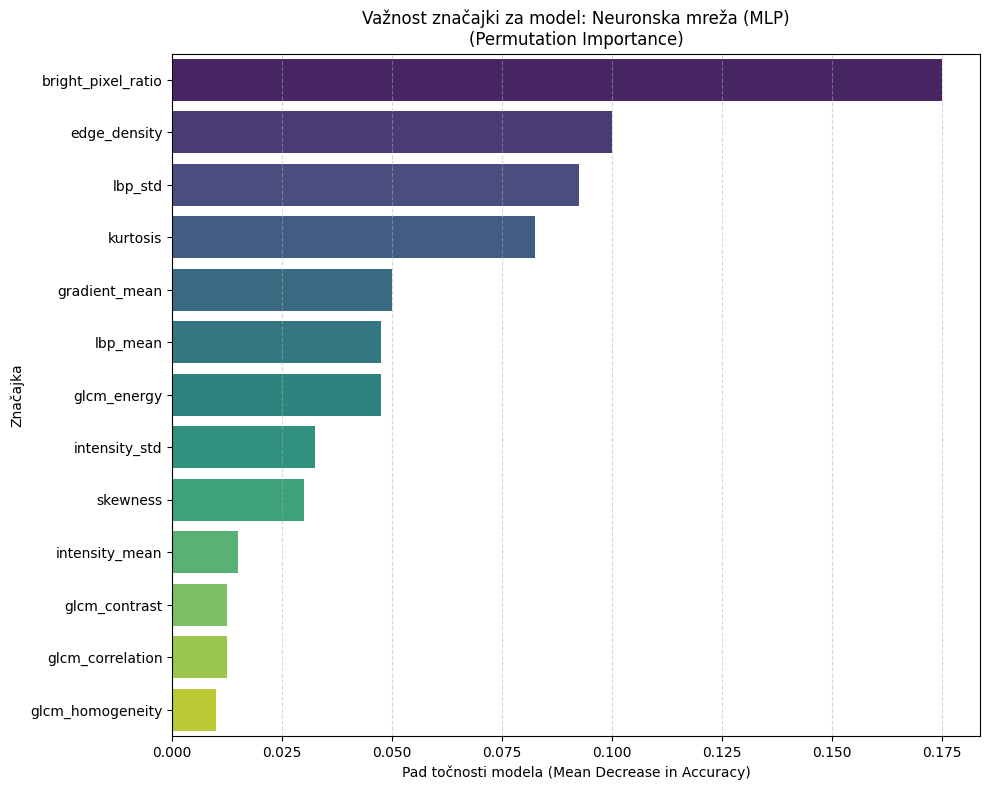

               Feature  Importance       Std
4   bright_pixel_ratio      0.1750  0.060208
6         edge_density      0.1000  0.033541
12             lbp_std      0.0925  0.037165
3             kurtosis      0.0825  0.040389
5        gradient_mean      0.0500  0.029580
11            lbp_mean      0.0475  0.036142
9          glcm_energy      0.0475  0.037832
1        intensity_std      0.0325  0.029686
2             skewness      0.0300  0.029155
0       intensity_mean      0.0150  0.033912
7        glcm_contrast      0.0125  0.040697
10    glcm_correlation      0.0125  0.023049
8     glcm_homogeneity      0.0100  0.025495


In [ ]:
from sklearn.inspection import permutation_importance

perm_importance = permutation_importance(best_model, X_test, y_test, n_repeats=10, random_state=42)

df_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': perm_importance.importances_mean,
    'Std': perm_importance.importances_std
})

df_importance = df_importance.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=df_importance, palette='viridis')
plt.title(f'Važnost značajki za model: {best_model_name}\n(Permutation Importance)')
plt.xlabel('Pad točnosti modela (Mean Decrease in Accuracy)')
plt.ylabel('Značajka')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print(df_importance)

Analiza važnosti značajki (feature importance) potvrđuje da model odluke donosi na temelju klinički relevantnih obilježja, a ne šuma u podacima.

Najveći utjecaj na klasifikaciju ima Bright Pixel Ratio (0.175), što je u skladu s radiološkim karakteristikama akutnog krvarenja koje se na CT snimkama manifestira kao hiperdenzno (svijetlo) područje. Model je ispravno naučio detektirati prisutnost krvi primarno kroz intenzitet piksela.

Osim svjetline, model koristi gustoću rubova i teksturu kako bi razlikovao nepravilne granice krvarenja od drugih svijetlih struktura.



# 8. Vizualizacija rezultata

Kako bismo detaljnije procijenili kvalitetu modela, koristimo ROC krivulju (Receiver Operating Characteristic). Ovaj graf prikazuje odnos između:


*   True Positive Rate (Odziv): Sposobnost modela da točno detektira krvarenje.

*   False Positive Rate: Učestalost lažnih uzbuna (kada model zdravu osobu proglasi bolesnom).


Idealna krivulja prolazi što bliže gornjem lijevom kutu grafa (visok odziv, malo lažnih uzbuna). Kao mjera kvalitete koristi se AUC (Area Under the Curve):



*   AUC = 0.5: Model pogađa nasumično (kao bacanje novčića).
*   AUC > 0.9: Izvrstan model s visokom sposobnošću razlikovanja zdravih od bolesnih slika.






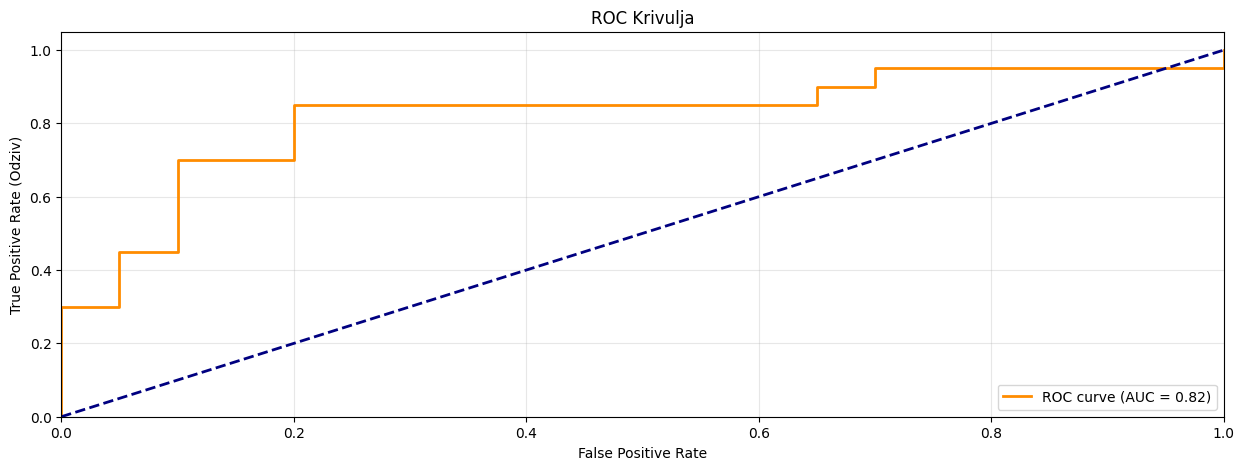

In [ ]:
from sklearn.metrics import roc_curve, auc
import seaborn as sns

y_pred_proba = best_model.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(15, 5))

plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Odziv)')
plt.title(f'ROC Krivulja')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

Analiziramo pouzdanost modela promatrajući distribuciju izlaznih vjerojatnosti.


*   Idealna situacija: Bimodalna distribucija s dva jasno razdvojena vrha – zdrave slike grupirane blizu 0, a krvarenja blizu 1.
*   Nesigurnost: Ako se distribucije preklapaju oko sredine (0.5), to ukazuje na to da model teško razlikuje određene slučajeve.




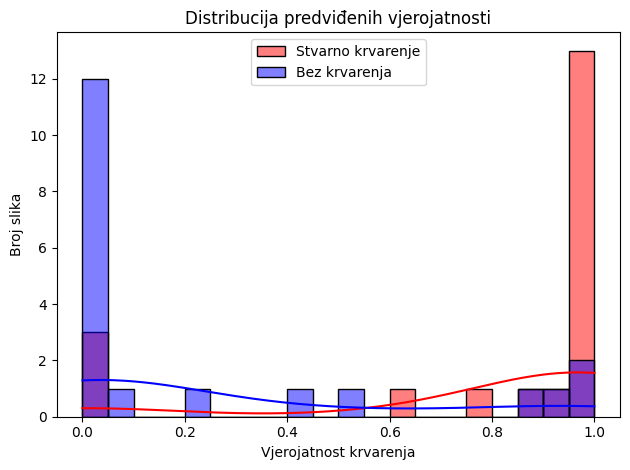

In [ ]:
sns.histplot(y_pred_proba[y_test==1], color='red', label='Stvarno krvarenje', kde=True, bins=20, alpha=0.5)
sns.histplot(y_pred_proba[y_test==0], color='blue', label='Bez krvarenja', kde=True, bins=20, alpha=0.5)
plt.title('Distribucija predviđenih vjerojatnosti')
plt.xlabel('Vjerojatnost krvarenja')
plt.ylabel('Broj slika')
plt.legend()
plt.tight_layout()
plt.show()

Provodimo kvalitativnu analizu pogrešaka vizualnim pregledom krivo klasificiranih slika:

*   False Negatives (FN): Propuštena krvarenja (najkritičnija greška). Analiziramo jesu li lezije premale ili niskog kontrasta.

*   False Positives (FP): Lažne uzbune. Provjeravamo jesu li šum ili artefakti zavarali model.




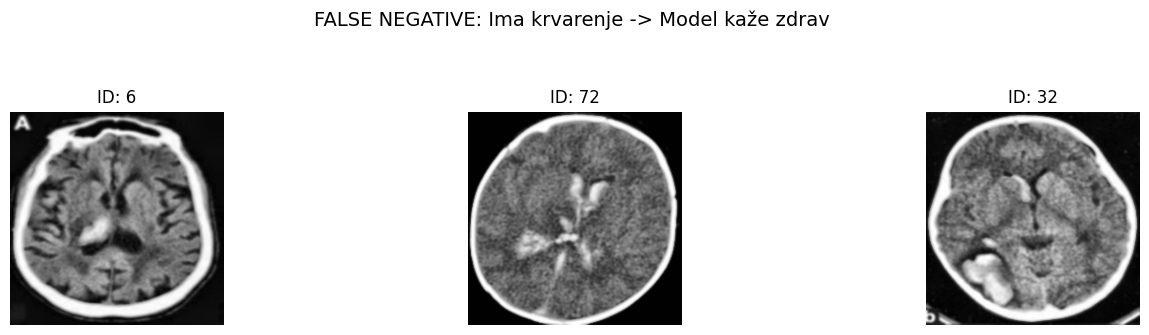

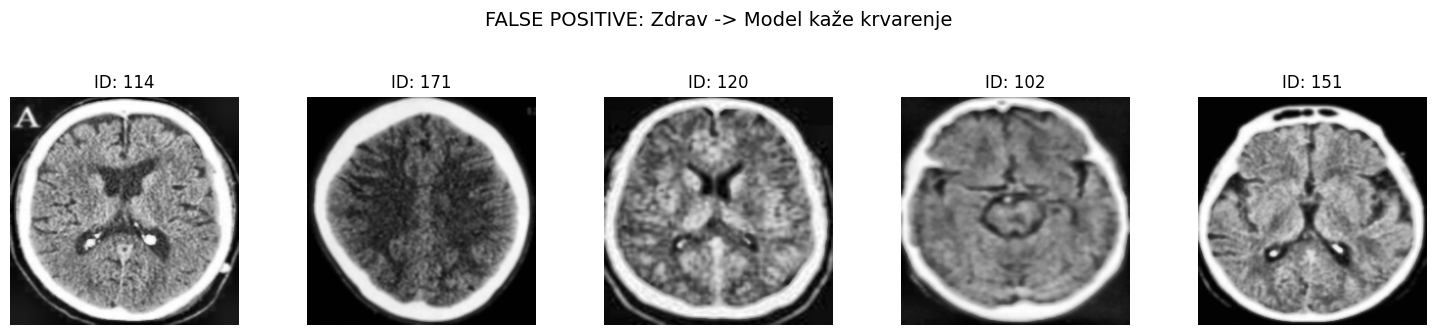

In [ ]:
test_indices = X_test.index
predictions = best_model.predict(X_test)

fn_indices = test_indices[(y_test == 1) & (predictions == 0)]
fp_indices = test_indices[(y_test == 0) & (predictions == 1)]

def show_errors(indices, title_text, max_imgs=5):
    if len(indices) == 0:
        print(f"Nema primjera za: {title_text}")
        return

    n = min(len(indices), max_imgs)
    plt.figure(figsize=(15, 3))
    plt.suptitle(f"{title_text}", fontsize=14, y=1.1)

    for i in range(n):
        idx = indices[i]
        img_path = df.loc[idx].path

        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        _, img_proc = preprocess_image(img)

        plt.subplot(1, n, i+1)
        plt.imshow(img_proc, cmap='gray')
        plt.axis('off')
        plt.title(f"ID: {df.loc[idx].id}")

    plt.tight_layout()
    plt.show()


show_errors(fn_indices, "FALSE NEGATIVE: Ima krvarenje -> Model kaže zdrav ")
show_errors(fp_indices, "FALSE POSITIVE: Zdrav -> Model kaže krvarenje")

---